In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps

import jlinops


import sys
import os

# Go three directories up
# current_dir = os.path.dirname(os.getcwd())
# three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..', ".."))
# sys.path.append(three_dirs_up)



from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])








from msolver import MMGKS, IASGKS, VanillaGKS
from fsolver import MMFGK, IASFGK
from pgkbsolver import MMGKB, IASGKB

#from pinv import CGWeightedNeumann2DPinvOperatorGPU

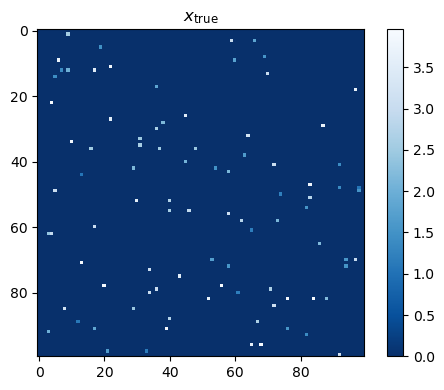

In [2]:
# Set example size
M, N = 100, 100
img_shape = (M,N)
n = M*N

# Draw random image
np.random.seed(1)
p = np.random.binomial(1, 0.01, size=img_shape).astype(np.float64)
q = np.random.uniform(low=1, high=4, size=img_shape).astype(np.float64)
ground_truth = (p*q).flatten()
x_true = ground_truth.copy()

plt.figure(figsize=(5,4))
plt.imshow(ground_truth.reshape(img_shape), cmap="Blues_r")
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.tight_layout()
plt.show()

/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_45145/440314591.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


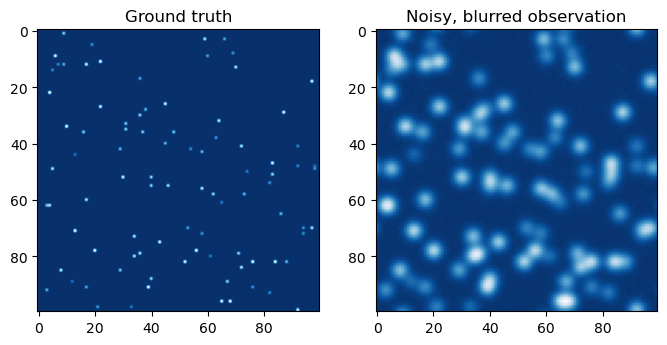

In [3]:
# Make blurring operator
blur_sigma = np.array(2.0).astype(np.float64) # standard deviation of the blur
A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0)

# Generate synthetic data
np.random.seed(0)
b_true = A @ ground_truth
noise_sigma = 0.1
b = b_true + noise_sigma*np.random.normal(size=A.shape[0])
b_noisy = b.copy()

noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])



# # Blurred image
# blurred_image = A.matvec_shaped(image)

# # Add some noise
# noise_sigma = 0.03*np.amax(blurred_image)
# noise_var = noise_sigma**2
# noisy_image = blurred_image + noise_sigma*np.random.normal(size=image.shape)
# b = noisy_image.flatten()

# Plot
fig, axs = plt.subplots(1, 2, figsize=(8,5))
axs[0].imshow(ground_truth.reshape(img_shape), cmap="Blues_r")
axs[0].set_title("Ground truth")
axs[1].imshow(b.reshape(img_shape), cmap="Blues_r")
axs[1].set_title("Noisy, blurred observation")
fig.show()

# Set up solvers

In [5]:
# Set method
method = "dp"

#Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
#L = jlinops.Neumann2D(img_shape)
L = jlinops.IdentityOperator((n,n))

def Lpinv_factory(w):
    return jlinops.DiagonalOperator(w)

K = None



weight_params = {
    "hyperpr_r": -1,
    "hyperpr_beta": 1,
}


# Build solvers
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=None, img_shape=img_shape)
mmgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)


# Run all solvers

In [6]:
vdata = gks_solver.solve(n_iter=75, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})


1e-14
1e-14
1e-14


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
9.194383479263808
46.17483535503653
62.901940121216214
71.96278440200167
79.37798238825837
88.56963751456105
96.59744461530924
100.29228497696602
105.80526047047816
113.16323470031048
116.30563689419317
120.01704528628368
124.4702843919624
127.43852542141784
129.53322544507319
132.19433563403416
133.9936332494562
136.12306111497648
137.99553745300707
140.09819200094967
140.93485448357742
143.1190791834307


In [7]:
data = mmgks_solver.solve(n_iter=75, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

print("Finished S-GKS.")

resdata = mmgks_solver.solve(n_iter=150, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=15)

print("Finished restarting S-GKS.")


recdata = mmgks_solver.solve(n_iter=150, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

print("Finished recycling S-GKS.")

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=75, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

print("Finished PS-GKS.")

respdata = mmgks_solver.solve_with_priorconditioning(n_iter=150, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01}, restart_dim=5)

print("Finished restarted PS-GKS.")





mmfkdata = mmfk_solver.solve(n_iter=75, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


rmmfkdata = mmfk_solver.solve(n_iter=75, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )



mmgkbdata = mmgkb_solver.solve(n_iter=75, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")



Augmented basis with initial guess!


61.345889674945
166.28801629948327
240.75020743680324
244.6023091248624
230.75501585082063
203.39003996137217
169.64134559563905
145.6094175432115
135.7475486120202
129.18394184775764
124.17881545944148
123.03161120877061
124.36932938637918
127.24530373082942
133.76033767866477
142.53222612122948
154.20270269593152
165.07740339490596
187.79143690617045
222.22795958149771
261.55481141493783
323.6415083235111
393.26085447654924
454.64857204732925
517.8166287368158
591.2214768172995
648.8797973490864
702.5385175703349
730.4844231129898
740.7721300615082
760.5307111297531
790.8776921986062
834.2528293906178
857.5586577584717
878.8637915090175
889.7656125485522
898.877145901929
921.3571311787344
953.0817467460263
999.2762614628601
1044.722121617003
1084.4645898971605
1124.8247462273137
1192.4058509589331
1231.740275824854
1236.9462641819684
1216.5007654386604
1177.3997199915104
1154.017558509847
1175.4053743199665
1210.8770390787743
1265.057465230645
1332.5562836314166
1415.5824516323657
14

61.345889674945
166.28801629948327
240.75020743680324
244.6023091248624
230.75501585082063
203.39003996137217
169.64134559563905
145.6094175432115
135.7475486120202
130.4129616884842
563.8746291920082
655.8353168317965
565.5835794512288
450.91020258038344
342.85265565319185
284.18014919864385
247.8257571830154
223.1918867282185
208.3522442298293
199.32456402935995
194.35192331048538
193.79875086788462
193.18407566392577
192.60696255554194
729.9148266532752
736.1944629775749
595.0185515972217
463.7366694019496
389.2361997107322
352.5972149951934
330.4671251601033
323.13072986202195
316.3284780780065
304.836907500232
298.48857115633956
291.6527133078372
278.8108353913946
270.8971613347261
1104.846002265252
961.3650129586827
741.8654767435629
570.0533158922053
467.66489994145746
416.24312944353403
391.71236380311734
386.2391095737197
379.71400056455656
378.46901198812094
389.0215988828201
394.3353349868917
384.2222574514213
377.2180609930668
1560.1394611170417
1164.8091909980726
821.64211

61.345889674945
166.28801629948327
240.75020743680324
244.6023091248624
230.75501585082063
203.39003996137217
169.64134559563905
145.6094175432115
135.7475486120202
129.18394184775764
124.17881545944148
123.03161120877061
124.36932938637918
127.24530373082942
133.76033767866477
142.53222612122948
154.20270269593152
165.07740339490596
187.79143690617045
222.22795958149771
261.55481141493783
323.6415083235111
393.26085447654924
454.64857204732925
517.8166287368158
591.2214768172995
648.8797973490864
702.5385175703349
730.4844231129898
740.7721300615082
760.5307111297531
790.8776921986062
834.2528293906178
857.5586577584717
878.8637915090175
889.7656125485522
898.877145901929
921.3571311787344
953.0817467460263
999.2762614628601
1044.722121617003
1084.4645898971605
1124.8247462273137
1192.4058509589331
1231.740275824854
1236.9462641819684
1216.5007654386604
1177.3997199915104
1154.017558509847
1175.4053743199665
1210.8770390787743
1265.057465230645
1332.5562836314166
1415.5824516323657
14

1e-14


...

generating basis...: 100%|██████████| 74/74 [00:00<00:00, 859.48it/s]


315.63953770120963


generating basis...: 100%|██████████| 75/75 [00:00<00:00, 1016.23it/s]

1e-06


Finished P-GKB


# Performance

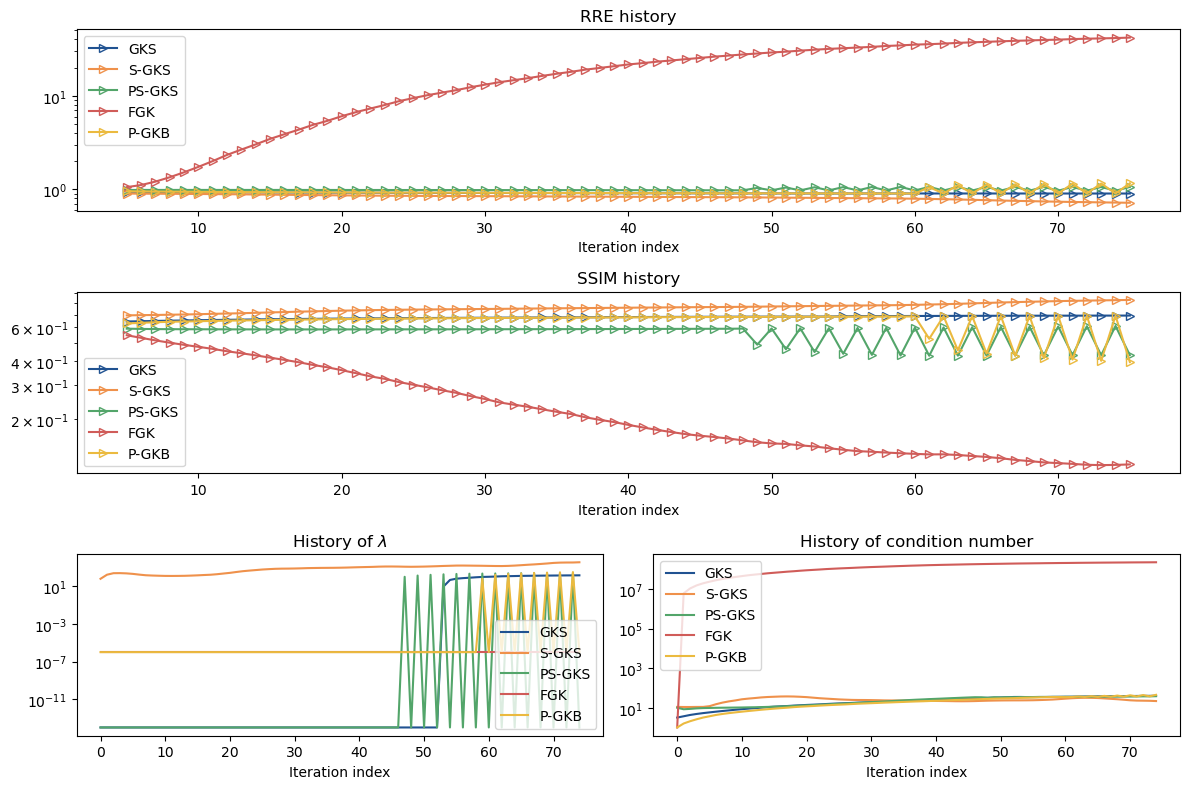

In [8]:
fig = plt.figure(figsize=(12,8) )

gs = gridspec.GridSpec(3, 2, figure=fig)

start_idx = 5
marker = ">"
markerfacecolor = 'none'

ax4 = fig.add_subplot(gs[0, :])
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))],  vdata["rre_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["rre_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["rre_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["rre_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["rre_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax4.legend()
ax4.set_xlabel("Iteration index")
ax4.set_title("RRE history")



ax3 = fig.add_subplot(gs[1, :])
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], vdata["ssim_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["ssim_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["ssim_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["ssim_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["ssim_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax3.legend()
ax3.set_xlabel("Iteration index")
ax3.set_title("SSIM history")

# ax3 = fig.add_subplot(gs[1, :])
# ax3.semilogy(vdata["haar_history"][start_idx:], label="GKS")
# ax3.semilogy(data["haar_history"][start_idx:], label="S-GKS")
# ax3.semilogy(pdata["haar_history"][start_idx:], label="PS-GKS")
# ax3.semilogy(mmfkdata["haar_history"][start_idx:], label="FGK")
# ax3.semilogy(mmgkbdata["haar_history"][start_idx:], label="P-GKB")
# ax3.legend()


ax1 = fig.add_subplot(gs[2, 0])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(mmfkdata["lambda_history"], label="FGK", color="C6")
ax1.semilogy(mmgkbdata["lambda_history"], label="P-GKB", color="C1")
ax1.legend(loc="lower right")
ax1.set_title("History of $\lambda$")
ax1.set_xlabel("Iteration index")



ax2 = fig.add_subplot(gs[2, 1])
ax2.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax2.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax2.semilogy(pdata["cond_ests"], label="PS-GKS", color="C4")
ax2.semilogy(mmfkdata["cond_ests"], label="FGK", color="C6")
ax2.semilogy(mmgkbdata["cond_ests"], label="P-GKB", color="C1")
ax2.legend(loc="upper left")
ax2.set_title("History of condition number")
ax2.set_xlabel("Iteration index")

fig.tight_layout()
fig.savefig("2d_points_performance_ias.png", dpi=250, bbox_inches=None)
fig.savefig("2d_points_performance_ias.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Reconstructions

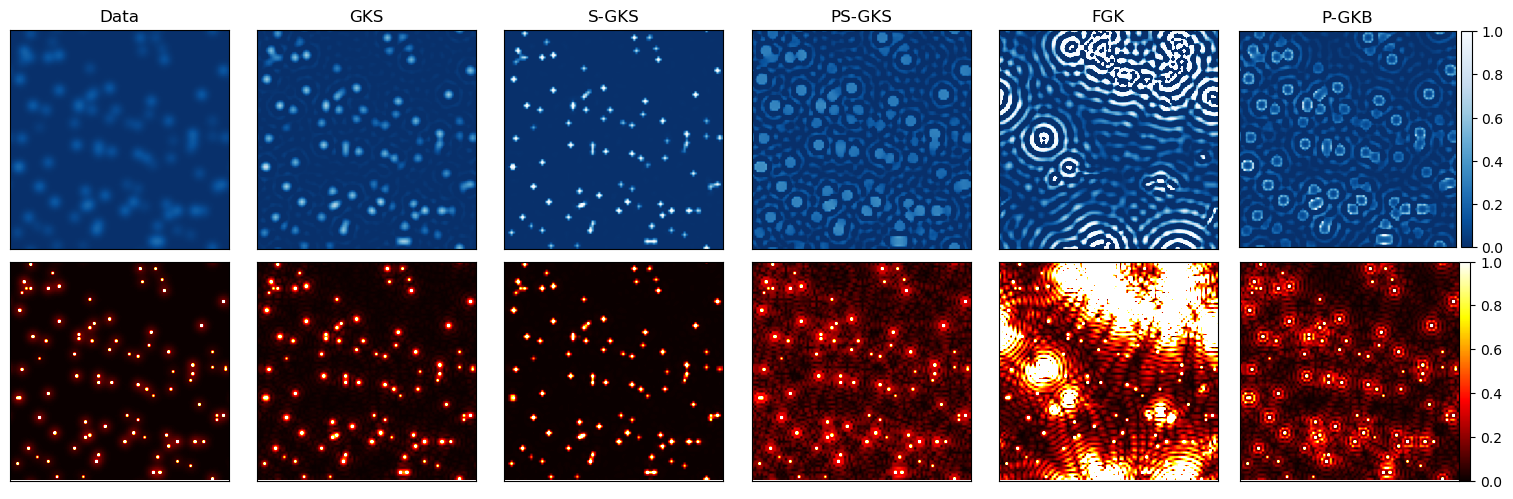

In [9]:
err_cmap = "hot"
plot_cmap = "Blues_r"

vbound = 1.0

fig, axs = plt.subplots(2,6,figsize=(15.3,5))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,1].set_title("GKS")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(data["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,2].set_title("S-GKS")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkdata["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,4].set_title("FGK")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# PS-GKS restarting
im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,5].set_title("P-GKB")
axs[0,5].set_xticks([])
axs[0,5].set_yticks([])
divider = make_axes_locatable(axs[0,5])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,5].set_xticks([])
axs[1,5].set_yticks([])
divider = make_axes_locatable(axs[1,5])
cax = divider.append_axes("right", size="5%", pad=0.00)
fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_points_reconstructions_ias.png", dpi=250, bbox_inches=None)
fig.savefig("2d_points_reconstructions_ias.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Basis vectors

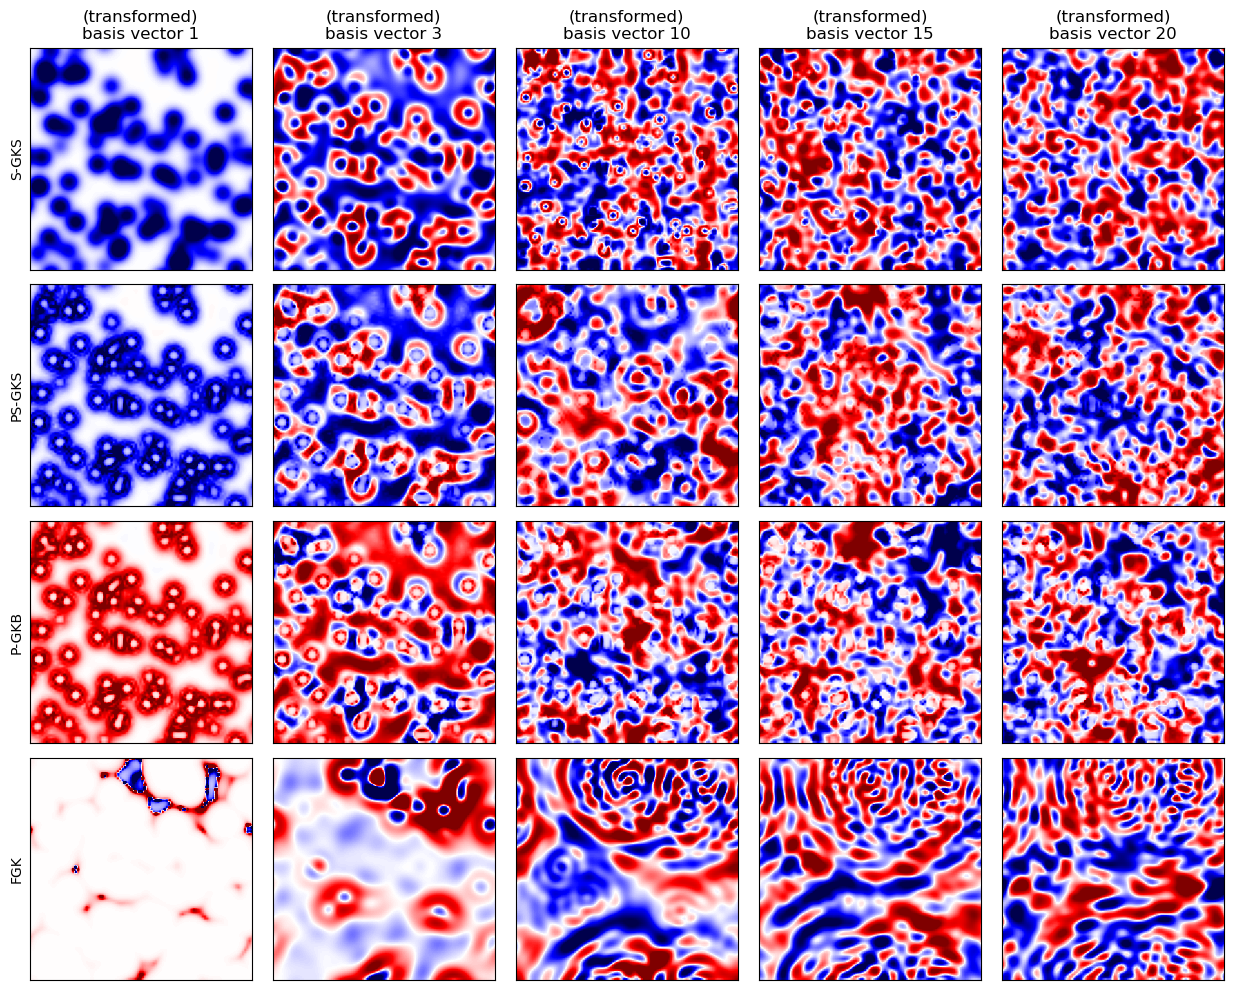

In [10]:
cmap = "seismic"
vbound = 0.1*0.189

kks = [0, 2, 9, 14, 19]

fig, axs = plt.subplots(4,5,figsize=(12.5,10))

for j, kk in enumerate(kks):

    axs[0,j].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[0,j].set_title(f"S-GKS basis vector {kk+1}")
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    if j == 0:
        axs[0,0].set_ylabel(f"S-GKS")
    axs[0,j].set_title(f"(transformed)\nbasis vector {kk+1}")


for j, kk in enumerate(kks):

    axs[1,j].imshow( ( (pdata["Lopinv"] @ pdata["V"][:,kk])/np.linalg.norm(pdata["Lopinv"] @ pdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
    if j == 0:
        axs[1,j].set_ylabel(f"PS-GKS")


for j, kk in enumerate(kks):

    axs[2,j].imshow( ( (mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk])/np.linalg.norm(mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
    if j == 0:
        axs[2,j].set_ylabel(f"P-GKB")



for j, kk in enumerate(kks):

    axs[3,j].imshow( ( mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
    if j == 0:
        axs[3,j].set_ylabel(f"FGK")


fig.tight_layout()

fig.savefig("2d_points_basis_vectors_ias.png", dpi=250, bbox_inches=None)
fig.savefig("2d_points_basis_vectors_ias.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Old plots

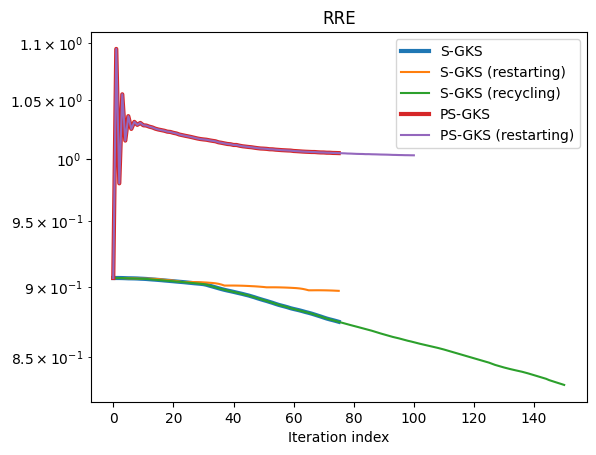

In [43]:
#plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["rre_history"], label="S-GKS", lw=3)
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)")
plt.semilogy(pdata["rre_history"], label="PS-GKS", lw=3)
plt.semilogy(respdata["rre_history"], label="PS-GKS (restarting)")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

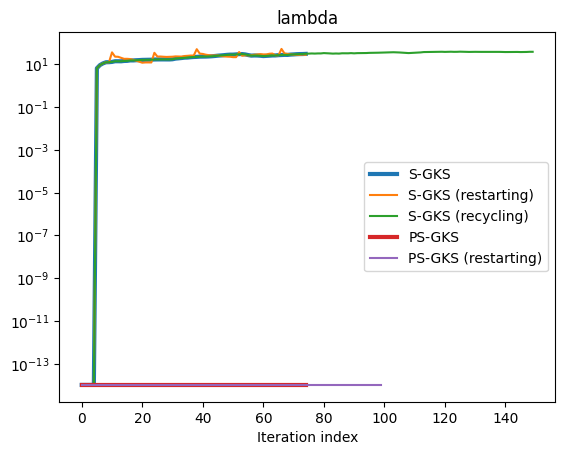

In [44]:
#plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS", lw=3)
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", lw=3)
plt.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)")
plt.title("lambda")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

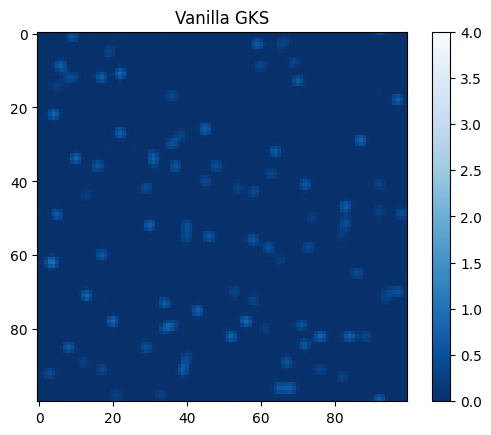

In [45]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

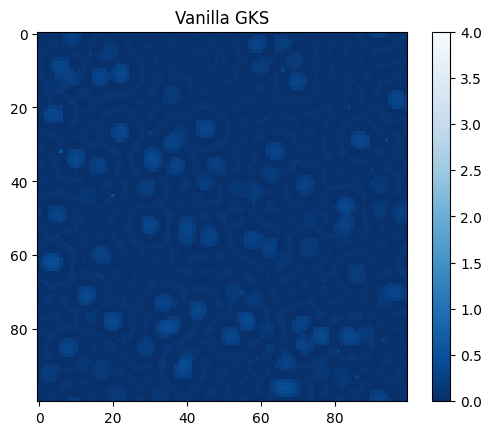

In [46]:
plt.imshow(pdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

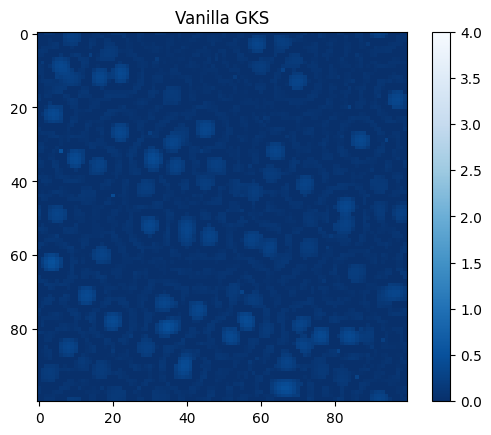

In [47]:
plt.imshow(respdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

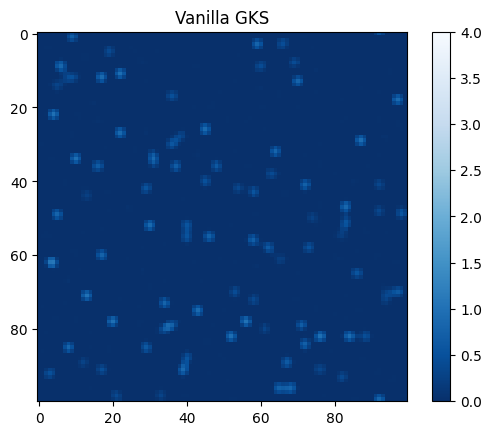

In [48]:
plt.imshow(recdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

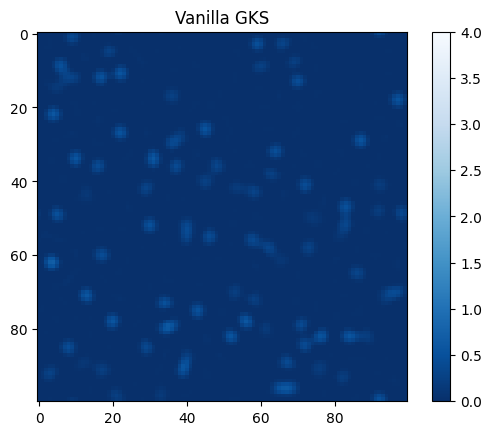

In [37]:
plt.imshow(resdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

# Old

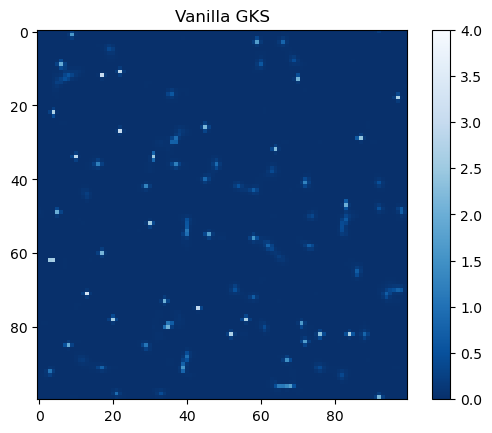

In [23]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

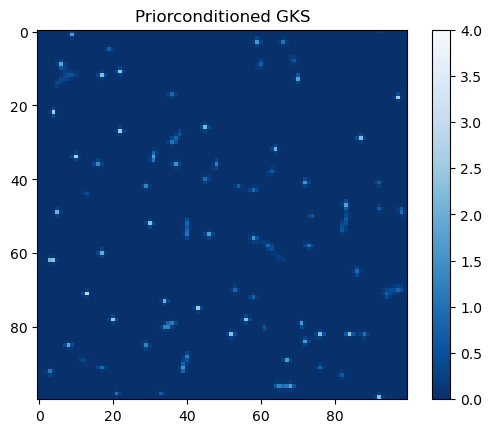

In [29]:
plt.imshow(pdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

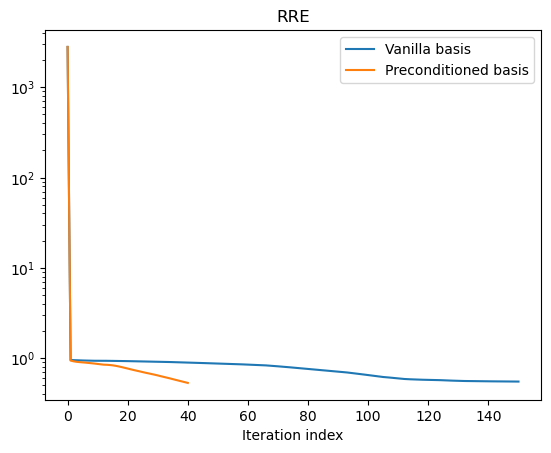

In [27]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

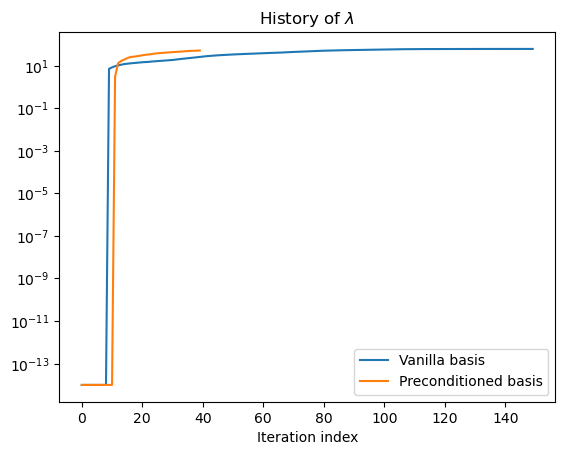

In [26]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

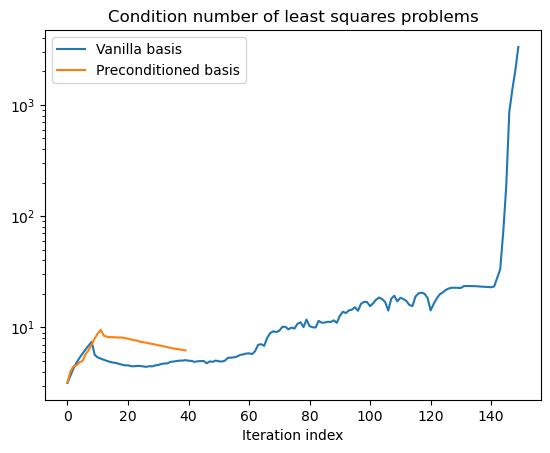

In [25]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# IAS example

In [77]:
n_iters = 200

# weight_params = {
#     "hyperpr_r": 1.0,
#     "hyperpr_beta": 1.5 + 1e-9,
# }

weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

In [80]:
# Set method
method = "dp"

# Build solver
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


# # Run the solver
# ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


In [81]:
data = iasgks_solver.solve(n_iter=60, init_dim=5, x0=None, lambdah0=1e0, lambdah_max=1e7,
                                    regparam=method, x_true=image.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = iasgks_solver.solve_with_priorconditioning(n_iter=60, init_dim=5, x0=None, lambdah0=1e0, lambdah_max=1e7,
                                                 regparam="dp", x_true=image.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
9.467149935847033
27.118985709168715
45.65587490365957
62.362043251342456
77.59662013253595
92.26863261612445
105.31007822104877
116.12223823864205
124.7868006466447
135.31419179784382
146.85623521033858
160.0401895640133
174.7074343573647
195.75029356445472
231.28069466728147
273.7620994787222
316.57489033725875
364.2742096611241
418.62611109737463
489.29639712301037
537.1812694951551
595.4335665710255
629.1451520584915
645.2171415778886
649.6444334574664
718.9600418002854
744.2526025354924
827.122338413305
861.8415008305542
931.2425012132194
921.9479420670381
1002.0984977847224
1017.4001040720814
994.7871964032231
1078.547984861973
1099.9445920809706
1069.9673805481107
1161.1047683127128
1044.0451718306192
1351.66060160509
853.0075220817574
1091.240119308039
922.4922704970847
1078.8848563445442
1029.0609452813471
951.5734888277361
1010.3324769321263
954.44283372963
1030.0281239186304
965.1086180010684
1004.0394154760099


1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
13.870406721749893
1e-06
24.725919500613795
1e-06
30.49741109612299
53.556704388541895
56.660574954361984
94.46630552345485
144.60342068006463
180.08376256099393
252.09088559241758
301.8974116802701
341.70850329382426
240.8774744674166
72.70196750623187
170.40159679391914
264.0003977389446
260.9680711584005
1e-06
33.80998109026222
78.41403689437186
147.52209551987033
262.1390927504261
480.11986112970294
749.1477577180548
559.3700925891021
1e-06
35.984501928540595
87.72594649760858
180.30731228033918
381.8000762248068
714.9065887148595
709.5286775231243
245.32985494838567
295.5952500382791
292.7938322639731
249.28903575269015
248.00914673448654
289.78829959730916
384.44978488082705
227.37803675872274
471.42888350033354
427.4108350835809
490.09984143192906
266.6074254346446
513.5734149812935
384.2591975448697
698.2042103246083
96.6092536640195
652.694540580394


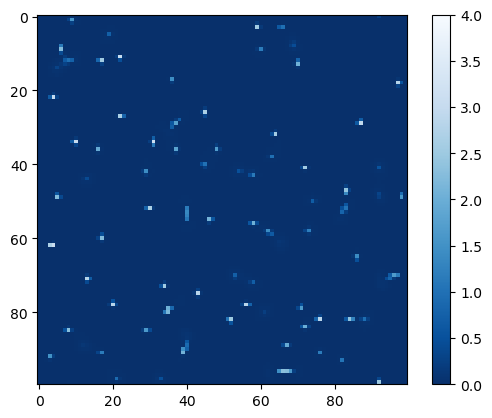

In [82]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.colorbar()
plt.show()

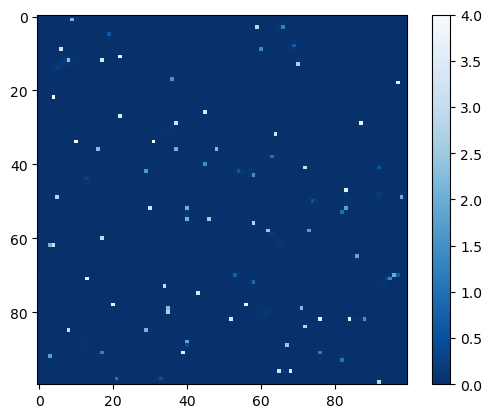

In [83]:
plt.imshow(pdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.colorbar()
plt.show()

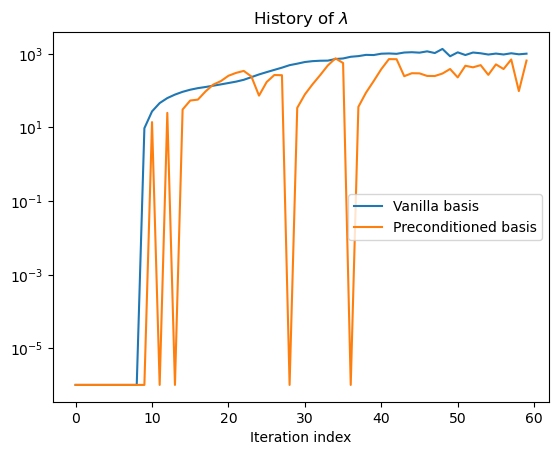

In [84]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

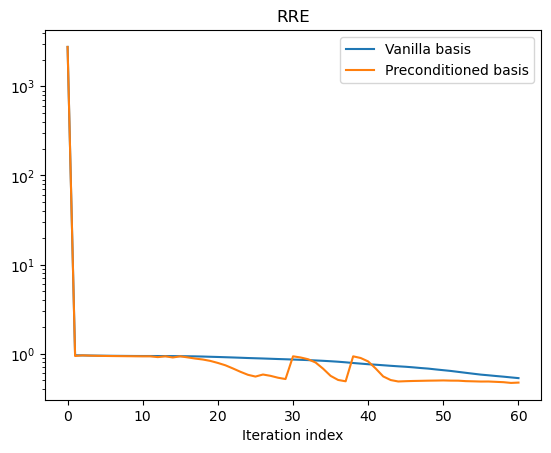

In [85]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()